# 3. Comparing physics variants against DR3, and predicting DR4

Runs stages 2-3 for both cached populations, then compares them with published DR3 results.
If `data/dr3_astrometric_orbits.csv.gz` exists (run `scripts/fetch_dr3_orbits.py` where the Gaia
archive is reachable), the observed dark-companion orbits are overplotted automatically.

**Reference points** (not fitted): about 3,200 WD + luminous-companion orbits in DR3
(Shahaf et al. 2024); intrinsic dN/dP ∝ P^-0.25 on 100-1000 d, and a WD mass peak near 0.6 Msun
(Yamaguchi, El-Badry & Shahaf 2025).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

In [2]:
from popsynth import analysis, plots

In [3]:
res = {t: analysis.run_pipeline(t, seed=7) for t in ["fiducial", "alpha5"]}
obs = analysis.load_observed()
print("observed DR3 sample:", "loaded" if obs is not None else "not available (published reference values only)")

observed DR3 sample: not available (published reference values only)


In [4]:
summary = pd.DataFrame({t: analysis.summarise(r) for t, r in res.items()})
rows = {
    "frac_wdms_sim_P_100_1000": "share of all WD+MS at P = 100-1000 d",
    "intrinsic_dndp_slope_100_1000": "intrinsic dN/dP slope, 100-1000 d (obs: -0.25)",
    "n_detected_DR3": "DR3 detections after triage (obs: ~3,200)",
    "frac_P_100_1000_DR3": "...of which P = 100-1000 d",
    "m_wd_median_DR3": "median WD mass, DR3 (obs peak ~0.6)",
    "frac_had_ce_DR3": "share that went through CE, DR3",
    "n_detected_DR4": "DR4 detections after triage",
    "frac_had_ce_DR4": "share that went through CE, DR4",
    "n_unique_sim_DR3": "distinct simulated systems behind DR3 detections",
}
summary.loc[list(rows)].rename(index=rows).astype(float).round(3)

,fiducial,alpha5
share of all WD+MS at P = 100-1000 d,0.007,0.047
"intrinsic dN/dP slope, 100-1000 d (obs: -0.25)",-2.680,-1.850
"DR3 detections after triage (obs: ~3,200)",5706.000,28490.000
...of which P = 100-1000 d,0.347,0.803
"median WD mass, DR3 (obs peak ~0.6)",0.590,0.638
"share that went through CE, DR3",0.308,0.883
DR4 detections after triage,44682.000,87271.000
"share that went through CE, DR4",0.073,0.551
distinct simulated systems behind DR3 detections,319.000,1088.000


The last row matters: the detected samples are built from a few hundred to a thousand
distinct simulated systems, each cloned about 1,500 times across the volume. Shapes are lumpy at
this sample size. Scale up the zero-age population (or importance-sample in period) before
quantitative fits.

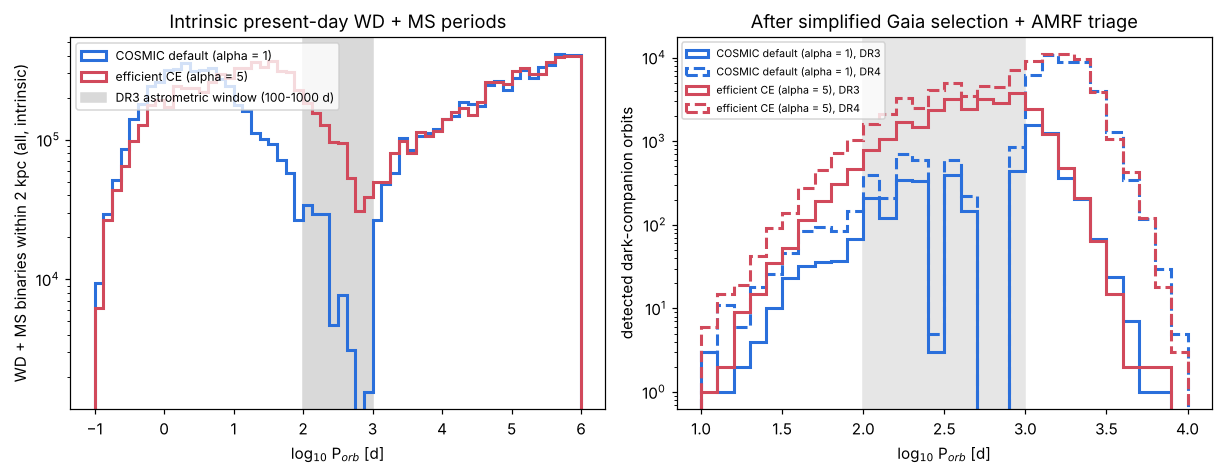

In [5]:
plots.period_distributions(res, obs)
plt.show()

**Left:** the default model (blue) leaves the 100-1000 d window almost empty, the long-known
tension. Efficient CE (red) fills it. **Right:** after the Gaia selection, alpha = 5 puts most
detections inside the window, but too many of them: its intrinsic period distribution falls far more
steeply (slope about -1.9) than the observed -0.25. That agrees with Yamaguchi et al. (2025): the alpha
formalism alone does not reproduce the data, which points to AGB mass-transfer stability as the next
physics to vary (`qcflag` / `qcrit_array`).

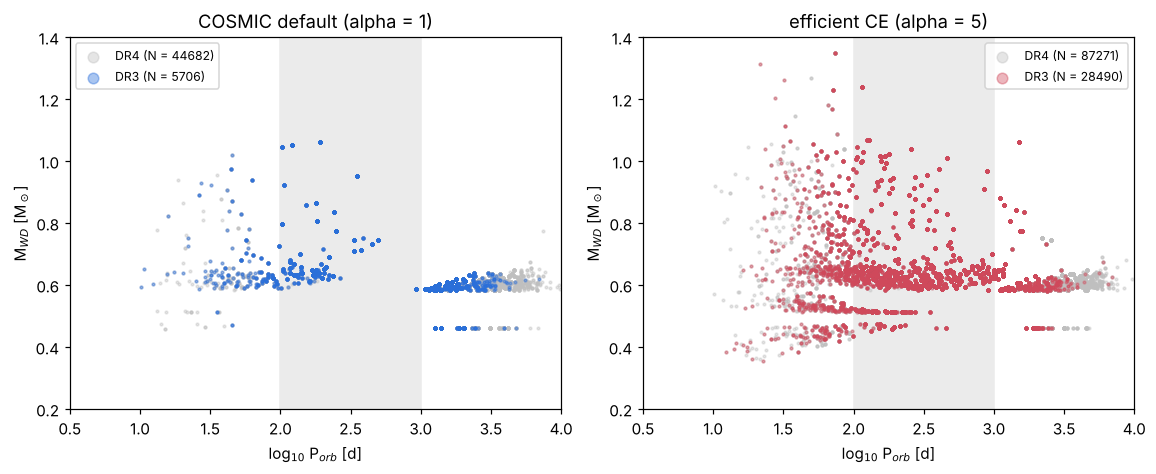

In [6]:
plots.period_vs_wd_mass(res)
plt.show()

## A DR4 prediction

DR4's 66-month baseline roughly doubles the accessible periods. In both variants most of the new
detections are at P > 1000 d and **never interacted**: with alpha = 1 the CE share among detections falls
from about 31% (DR3) to about 7% (DR4). Where the boundary between interacting and non-interacting systems
falls in DR4 is a direct, testable prediction.

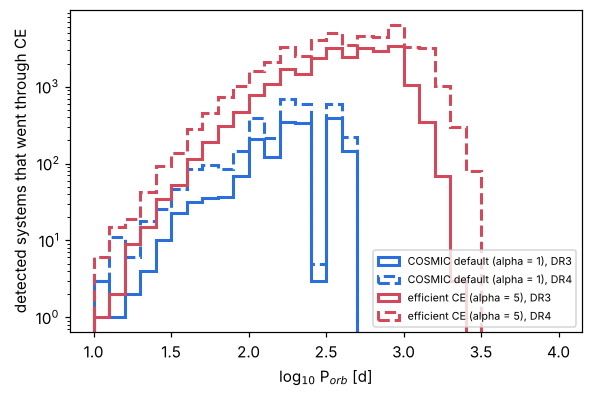

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.8))
bins = np.linspace(1, 4, 31)
for t, r in res.items():
    for rel, ls in (("DR3", "-"), ("DR4", "--")):
        d = r[rel][r[rel].wd_class]
        ax.hist(np.log10(d.porb), bins=bins, weights=d.had_ce.astype(float), histtype="step", lw=2, ls=ls,
                color=analysis.COLORS[t], label=f"{analysis.LABELS[t]}, {rel}")
ax.set_yscale("log"); ax.set_xlabel("log$_{10}$ P$_{orb}$ [d]"); ax.set_ylabel("detected systems that went through CE")
ax.legend(fontsize=7)
plt.show()

## Caveats and next steps

1. **Counts are not yet comparable.** The triage is looser than the published selection, and the
   normalisation is uncertain at about 2×. Compare shapes first.
2. **Swap in gaiamock** for `gaia.select` and check the mock reproduces the DR3 period peak near 550 d.
3. **Vary AGB mass-transfer stability and WD kicks**, not only alpha. Eccentricities are the next observable.
4. **DR4** (2 December 2026): rerun with `GaiaRelease.dr4()` and validate on the DR4 pre-release epoch
   astrometry sample.